In [2]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
import warnings
import joblib
warnings.filterwarnings("ignore")

In [3]:
# Perform k-means clustering and vector quantization
from scipy.cluster.vq import kmeans, vq
from sklearn.preprocessing import StandardScaler
import pylab as pl
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score #sreeni
#import sklearn.external.joblib as extjoblib

In [4]:
GROUP = "C5"
DTYPE="ORB"
MODEL ="RF"
scale = 15
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C5_10,28,"[DATA/TRAINING/C5/C5_10/IMG_7698.HEIC, DATA/TR..."
1,C5_11,30,"[DATA/TRAINING/C5/C5_11/IMG_7771.HEIC, DATA/TR..."
2,C5_12,26,"[DATA/TRAINING/C5/C5_12/IMG_7848.HEIC, DATA/TR..."
3,C5_13,27,"[DATA/TRAINING/C5/C5_13/IMG_7909.HEIC, DATA/TR..."
4,C5_14,27,"[DATA/TRAINING/C5/C5_14/IMG_7973.HEIC, DATA/TR..."
5,C5_15,28,"[DATA/TRAINING/C5/C5_15/IMG_8037.DNG, DATA/TRA..."
6,C5_16,23,"[DATA/TRAINING/C5/C5_16/IMG_8106.HEIC, DATA/TR..."


In [5]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [6]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [7]:
def resize_image(img, scale_percent=10):
    #scale_percent = 10 # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [8]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

Text(0.5, 1.0, '16% IMG_8132.HEIC')

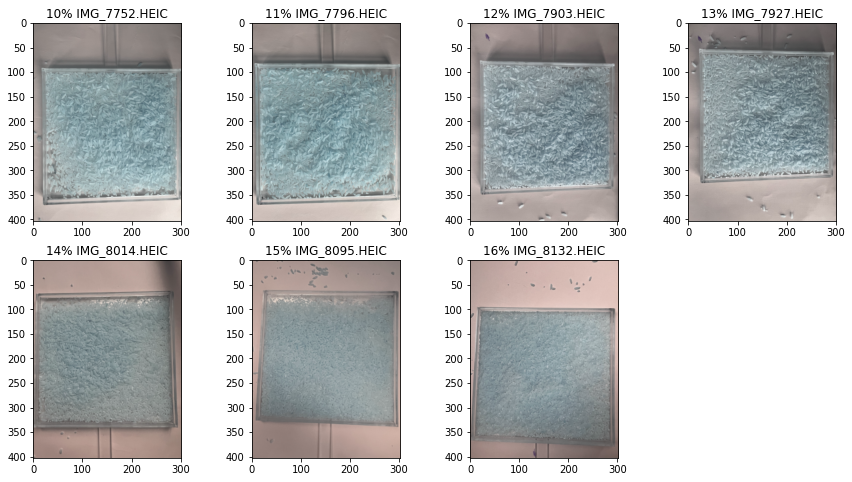

In [9]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [10]:
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
data = []
data_path_= []; image_classes_=[]
class_id = 10
for folder in HH_path:
    class_id=folder.split("_")[1]
    #print(class_id)
    path_GHH = GROUP_path+folder+"/"
    #print(class_id, path_GHH)
    images = os.listdir(path_GHH)
    #print(images)
    training = [(path_GHH+i) for i in images]
    image_classes_ +=[int(class_id)]*len(training)
    #print(image_classes_)
    data_path_ += training
    data.append([class_id, len(images), images])
pdDT = pd.DataFrame(data)    # values
pdDT.columns = ["folder", "images", "files_path"]
pdDT


,folder,images,files_path
0,10,28,"[IMG_7698.HEIC, IMG_7701.HEIC, IMG_7702.HEIC, ..."
1,11,30,"[IMG_7771.HEIC, IMG_7775.HEIC, IMG_7776.HEIC, ..."
2,12,26,"[IMG_7848.HEIC, IMG_7850.HEIC, IMG_7853.HEIC, ..."
3,13,27,"[IMG_7909.HEIC, IMG_7912.HEIC, IMG_7913.HEIC, ..."
4,14,27,"[IMG_7973.HEIC, IMG_7975.HEIC, IMG_7978.HEIC, ..."
5,15,28,"[IMG_8037.DNG, IMG_8038.DNG, IMG_8041.DNG, IMG..."
6,16,23,"[IMG_8106.HEIC, IMG_8107.HEIC, IMG_8109.HEIC, ..."


In [11]:
#for x, y in zip(data_path_, image_classes_):
#    print(x, y)
X=np.array(data_path_)
y=np.array(image_classes_)
#X

In [12]:
lst_k = [125] #np.arange(25, 225, 25)
lst_k

[125]

In [13]:
from sklearn.model_selection import StratifiedKFold
kf = StratifiedKFold(n_splits=10, random_state=None, shuffle=True)

lst_res_data=[]
for k in lst_k:
    k_fold=1
    for train_index , test_index in kf.split(X, y):
        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        #print(k_fold, len(X_train), len(y_train), len(X_test), len(y_test))
        
        image_paths =X_train; image_classes =y_train
        
        des_list = []
        objLD  = cv2.ORB_create()
        for image_path in image_paths:
            im = read_image(image_path); 
            im = flip_image_vertical(im)
            im = resize_image(im, scale)
            gray= cv2.cvtColor(im,cv2.COLOR_BGR2GRAY)

            kp = objLD.detect(gray,None)
            kp, des = objLD.compute(gray, kp)
            des_list.append((image_path, des))
        
        descriptors = des_list[0][1]
        for image_path, descriptor in des_list[1:]:
            descriptors = np.vstack((descriptors, descriptor))  
        #print(descriptors)
        
        descriptors_float = descriptors.astype(float)  
        voc, variance = kmeans(descriptors_float, k, 1) 
        
        im_features = np.zeros((len(X_train), k), "float32")
        for i in range(len(X_train)):
            words, distance = vq(des_list[i][1],voc)
            for w in words:
                im_features[i][w] += 1
        
        # Perform Tf-Idf vectorization
        nbr_occurences = np.sum( (im_features > 0) * 1, axis = 0)
        idf = np.array(np.log((1.0*len(X_train)+1) / (1.0*nbr_occurences + 1)), 'float32')
        
        # Scaling the words - Standardize features by removing the mean and scaling to unit variance
        stdSlr = StandardScaler().fit(im_features)
        im_features = stdSlr.transform(im_features)
        #file_name = DTYPE+'_scale_'+str(GROUP)+'_'+str(k)+'_'+str(k_fold)+'.joblib'
        #joblib.dump(stdSlr, file_name)

        
        clf = RandomForestClassifier(n_estimators = 1000, random_state=0)
        clf.fit(im_features, np.array(y_train))
        joblib.dump((clf, image_classes, stdSlr, k, voc), DTYPE+'_model_'+str(MODEL)+"_"+str(GROUP)+'_'+str(k)+'_'+str(k_fold)+'.pkl', compress=3) 

        des_list = []
        for image_path in X_test:
            im = read_image(image_path); 
            im = flip_image_vertical(im)
            im = resize_image(im, scale)
            gray= cv2.cvtColor(im,cv2.COLOR_BGR2GRAY)
            
            kp = objLD.detect(gray,None)
            kp, des = objLD.compute(gray, kp)
            des_list.append((image_path, des)) 
            descriptors = des_list[0][1]
        
        for image_path, descriptor in des_list[0:]:
            descriptors = np.vstack((descriptors, descriptor)) 
        
        test_features = np.zeros((len(X_test), k), "float32")
        for i in range(len(X_test)):
            words, distance = vq(des_list[i][1],voc)
            for w in words:
                test_features[i][w] += 1
        
        
        nbr_occurences = np.sum( (test_features > 0) * 1, axis = 0)
        idf = np.array(np.log((1.0*len(X_test)+1) / (1.0*nbr_occurences + 1)), 'float32')

        test_features = stdSlr.transform(test_features)

        true_class =  [i for i in y_test]
        clf.predict(test_features)

        predictions =  [i for i in clf.predict(test_features)]
        accuracy = accuracy_score(true_class, predictions)
        #tn, fp, fn, tp = confusion_matrix(true_class, predictions, labels=[0,1]).ravel()

        precision =np.mean(precision_score(true_class, predictions, average=None, zero_division=1))
        recall =np.mean(recall_score(true_class, predictions, average=None, zero_division=1))
        F1 = 2 * (precision * recall) / (precision + recall)
        lst_res = [k, k_fold, accuracy, precision, recall, F1]
        #print(lst_res)
        lst_res_data.append(lst_res)
        k_fold=k_fold+1
        #break
    #break

In [14]:
dt_dimention_test = pd.DataFrame(lst_res_data)
dt_dimention_test.columns = ["k", "fold", "accuracy", "precision", "recall", "F1"]
#pd.set_option('display.max_rows', 200)
dt_dimention_test["MODEL"]= DTYPE
dt_dimention_test["GROUP"]= GROUP
dt_dimention_test["SCALE"]= scale
#dt_dimention_test.to_csv('RESULTS/LOCAL/CV/CV_'+str(scale)+'_'+GROUP+"_"+DTYPE+'.csv', index=False)

dt_dimention_test

,k,fold,accuracy,precision,recall,F1,MODEL,GROUP,SCALE
0,125,1,0.684211,0.700000,0.690476,0.695205,ORB,C5,15
1,125,2,0.684211,0.726190,0.666667,0.695157,ORB,C5,15
2,125,3,0.526316,0.640476,0.523810,0.576298,ORB,C5,15
3,125,4,0.631579,0.742857,0.619048,0.675325,ORB,C5,15
4,125,5,0.526316,0.600340,0.523810,0.559470,ORB,C5,15
5,125,6,0.684211,0.785714,0.666667,0.721311,ORB,C5,15
6,125,7,0.631579,0.702381,0.642857,0.671302,ORB,C5,15
7,125,8,0.631579,0.761905,0.666667,0.711111,ORB,C5,15
8,125,9,0.578947,0.642857,0.547619,0.591429,ORB,C5,15
9,125,10,0.666667,0.714286,0.690476,0.702179,ORB,C5,15


In [15]:
dt_dimention_test.groupby(['k'])[['accuracy', 'precision', 'recall', 'F1']].mean()

,accuracy,precision,recall,F1
k,,,,
125,0.624561,0.701701,0.62381,0.659879


# Testing

In [16]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []; image_clases=[]; image_paths=[]
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    class_id=HH.split("_")[1]
    images = os.listdir(path_GHH)
    
    path_images = [GROUP_path+HH+"/"+x for x in images]
    for x in path_images:
        image_paths.append(x)
        image_clases.append(class_id)
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C5_10,5,"[DATA/TEST/C5/C5_10/IMG_7696.HEIC, DATA/TEST/C..."
1,C5_11,5,"[DATA/TEST/C5/C5_11/IMG_7770.HEIC, DATA/TEST/C..."
2,C5_12,5,"[DATA/TEST/C5/C5_12/IMG_7847.HEIC, DATA/TEST/C..."
3,C5_13,5,"[DATA/TEST/C5/C5_13/IMG_7908.HEIC, DATA/TEST/C..."
4,C5_14,5,"[DATA/TEST/C5/C5_14/IMG_7971.HEIC, DATA/TEST/C..."
5,C5_15,5,"[DATA/TEST/C5/C5_15/IMG_8052.DNG, DATA/TEST/C5..."
6,C5_16,5,"[DATA/TEST/C5/C5_16/IMG_8103.HEIC, DATA/TEST/C..."


In [17]:
HH=['10', '11', '12', '13', '14', '15', '16']
testing_names = ["h10", "h11", "h12", "h13", "h14", "h15", "h16"]# os.listdir(test_path)
clf, classes_names, stdSlr, k, voc = joblib.load('models/ORB/ORB_model_RF_C5_125_6.pkl')
print(k)

125


In [18]:
des_list = []
objLD  = cv2.ORB_create()
for image_path_list in data_path_test:
    for image_path in image_path_list:
        im = read_image(image_path); 
        #im = cv2.imread(image_path)
        im = flip_image_vertical(im)
        im = resize_image(im, scale)
        gray= cv2.cvtColor(im,cv2.COLOR_BGR2GRAY)
    
        kp = objLD.detect(gray,None)
        kp, des = objLD.compute(gray, kp)
        des_list.append((image_path, des)) 
descriptors = des_list[0][1]
for image_path, descriptor in des_list[0:]:
    descriptors = np.vstack((descriptors, descriptor))

In [19]:
test_features = np.zeros((len(image_paths), k), "float32")
for i in range(len(image_paths)):
    words, distance = vq(des_list[i][1],voc)
    for w in words:
        test_features[i][w] += 1
# Perform Tf-Idf vectorization
nbr_occurences = np.sum( (test_features > 0) * 1, axis = 0)
idf = np.array(np.log((1.0*len(image_paths)+1) / (1.0*nbr_occurences + 1)), 'float32')
test_features = stdSlr.transform(test_features)
#Report true class names so they can be compared with predicted classes
true_class =  [int(i) for i in image_clases]
clf.predict(test_features)
# Perform the predictions and report predicted class names. 
predictions =  [int(i) for i in clf.predict(test_features)]
print(predictions)

[15, 10, 10, 11, 11, 12, 11, 11, 13, 11, 12, 12, 12, 13, 11, 14, 12, 12, 13, 13, 14, 14, 14, 14, 15, 15, 15, 15, 15, 15, 16, 16, 16, 15, 16]


In [20]:
accuracy = accuracy_score(true_class, predictions)
print ("accuracy = ", accuracy)
cm = confusion_matrix(true_class, predictions)
print (cm)

accuracy =  0.6571428571428571
[[2 2 0 0 0 1 0]
 [0 3 1 1 0 0 0]
 [0 1 3 1 0 0 0]
 [0 0 2 2 1 0 0]
 [0 0 0 0 4 1 0]
 [0 0 0 0 0 5 0]
 [0 0 0 0 0 1 4]]


In [21]:
from sklearn.metrics import classification_report
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(true_class, predictions, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.40      0.57         5
     Class 1       0.50      0.60      0.55         5
     Class 2       0.50      0.60      0.55         5
     Class 3       0.50      0.40      0.44         5
     Class 4       0.80      0.80      0.80         5
     Class 5       0.62      1.00      0.77         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.66        35
   macro avg       0.70      0.66      0.65        35
weighted avg       0.70      0.66      0.65        35



## Testing 

In [22]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C5_10,5,"[DATA/TEST/C5/C5_10/IMG_7696.HEIC, DATA/TEST/C..."
1,C5_11,5,"[DATA/TEST/C5/C5_11/IMG_7770.HEIC, DATA/TEST/C..."
2,C5_12,5,"[DATA/TEST/C5/C5_12/IMG_7847.HEIC, DATA/TEST/C..."
3,C5_13,5,"[DATA/TEST/C5/C5_13/IMG_7908.HEIC, DATA/TEST/C..."
4,C5_14,5,"[DATA/TEST/C5/C5_14/IMG_7971.HEIC, DATA/TEST/C..."
5,C5_15,5,"[DATA/TEST/C5/C5_15/IMG_8052.DNG, DATA/TEST/C5..."
6,C5_16,5,"[DATA/TEST/C5/C5_16/IMG_8103.HEIC, DATA/TEST/C..."


In [23]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [24]:
clf, classes_names, stdSlr, k, voc = joblib.load('models/ORB/ORB_model_RF_C5_125_6.pkl')
print(k)

125


In [25]:
testing_names = ["h10", "h11", "h12", "h13", "h14", "h15", "h16"]# os.listdir(test_path)


In [26]:
res_test=[]
objLD  = cv2.ORB_create()
for image_path_list in data_path_test:
    for image_path in image_path_list:
        #print(image_path)
        des_list = []
        im = read_image(image_path); 
        im = flip_image_vertical(im)
        im = resize_image(im, scale)
        gray= cv2.cvtColor(im,cv2.COLOR_BGR2GRAY)
        kp = objLD.detect(gray,None)
        kp, des = objLD.compute(gray, kp)
        des_list.append((image_path, des))  
            
        test_features = np.zeros((1, k), "float32")
        
        words, distance = vq(des_list[0][1],voc)
        for w in words:
            test_features[0][w] += 1

        #print(test_features.shape)
        test_features = stdSlr.transform(test_features)
        prediction = clf.predict(test_features)
        true_humidity=image_path.split("_")[1].split("/")[0]
        #print(image_path, true_humidity)
        image_name=image_path.split("/")[4]
        res_test.append([image_name, float(true_humidity), float(prediction[0])])

In [27]:
res_testDT= pd.DataFrame(res_test)
res_testDT.columns = ["image_name", "true", "prediction"]
res_testDT["MODEL"]= DTYPE
res_testDT["GROUP"]= GROUP
res_testDT["SCALE"]= scale
#res_testDT.to_csv('RESULTS/LOCAL/EV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
res_testDT.tail()

,image_name,true,prediction,MODEL,GROUP,SCALE
30,IMG_8103.HEIC,16.0,16.0,ORB,C5,15
31,IMG_8117.HEIC,16.0,16.0,ORB,C5,15
32,IMG_8133.HEIC,16.0,16.0,ORB,C5,15
33,IMG_8149.HEIC,16.0,15.0,ORB,C5,15
34,IMG_8156.HEIC,16.0,16.0,ORB,C5,15


In [28]:
accuracy = accuracy_score([float(x) for x in res_testDT["true"]], [float(x) for x in res_testDT["prediction"]])
print ("accuracy = ", accuracy)

accuracy =  0.6571428571428571


In [29]:
res = classification_report([float(x) for x in res_testDT["true"]], [float(x) for x in res_testDT["prediction"]])
print(res)


              precision    recall  f1-score   support

        10.0       1.00      0.40      0.57         5
        11.0       0.50      0.60      0.55         5
        12.0       0.50      0.60      0.55         5
        13.0       0.50      0.40      0.44         5
        14.0       0.80      0.80      0.80         5
        15.0       0.62      1.00      0.77         5
        16.0       1.00      0.80      0.89         5

    accuracy                           0.66        35
   macro avg       0.70      0.66      0.65        35
weighted avg       0.70      0.66      0.65        35

